# 36103 Statistical Thinking for Data Science
## Assessment Task 3: Data analysis project for marketing campaigns (code)

Student: Quang Trung Nguyen (26643559)

Code for the AT3 report. Run from top to bottom with `TeleCom_Data-2.csv` in the same folder.

Sections: 1 setup, 2 data checks and cleaning, 3 association tests, 4 train/test split, 5 logistic regression (MLE), 6 KNN, decision tree and gradient boosting, 7 model comparison, 8 interpreting the non-parametric models, 9 Bayesian estimation, 10 business insights, 11 fairness check, 12 hypothesis summary.

## 1. Setup and data loading

In [1]:
import io
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score, roc_curve,
                             precision_recall_curve)
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_val_predict,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.base import clone

warnings.filterwarnings("ignore")
SEED = 42

In [2]:
# The raw file wraps each row in quotes and doubles the inner quotes, so it is repaired before parsing
PATH = "TeleCom_Data-2.csv"
with open(PATH, encoding="utf-8-sig") as f:
    lines = f.read().splitlines()
fixed = []
for line in lines:
    line = line.rstrip("\r\n")
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]
    fixed.append(line.replace('""', '"'))
raw = pd.read_csv(io.StringIO("\n".join(fixed)), sep=";", quotechar='"')
print("Raw shape:", raw.shape)
raw.head(20)

Raw shape: (41180, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,29,blue-collar,single,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data quality checks and cleaning

### 2.1 Row order
The `month` column goes may, jun, ..., dec and then jumps back to mar two times, so the rows seem to be in time order. I number each month block (`period`) and split the rows into 3 phases at each jump. This is done before dropping duplicates so the order is kept. The public version of this data (Moro et al., 2014) covers May 2008 to Nov 2010, which fits 3 phases.

In [3]:
raw["period"] = (raw["month"] != raw["month"].shift()).cumsum()
raw["phase"] = np.select([raw["period"] <= 7, raw["period"] <= 17], [1, 2], default=3)
raw["row_order"] = np.arange(len(raw))
print("Number of month blocks:", raw["period"].max())
print(raw.groupby("period")["month"].first().tolist())

Number of month blocks: 26
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov']


### 2.2 Data quality summary

In [4]:
data_cols = [c for c in raw.columns if c not in ["period", "phase", "row_order"]]
checks = {
    "Exact duplicate rows": int(raw.duplicated(subset=data_cols).sum()),
    "Age range": f"{raw['age'].min()} to {raw['age'].max()}",
    "Rows with age > 90 (kept)": int((raw["age"] > 90).sum()),
    "pdays = 999 (never contacted code)": int((raw["pdays"] == 999).sum()),
    "pdays = 999 but previous > 0 (inconsistent)": int(((raw["pdays"] == 999) & (raw["previous"] > 0)).sum()),
    "default = 'yes'": int((raw["default"] == "yes").sum()),
    "education = 'illiterate'": int((raw["education"] == "illiterate").sum()),
    "housing and loan both 'unknown' (same rows)": int(((raw["housing"] == "unknown") & (raw["loan"] == "unknown")).sum()),
    "Target prevalence (yes)": round((raw["y"] == "yes").mean(), 4),
}
pd.Series(checks, name="value").to_frame()

,value
Exact duplicate rows,12
Age range,17 to 98
Rows with age > 90 (kept),10
pdays = 999 (never contacted code),39667
pdays = 999 but previous > 0 (inconsistent),4108
default = 'yes',3
education = 'illiterate',18
housing and loan both 'unknown' (same rows),990
Target prevalence (yes),0.1126


In [5]:
unknown = {c: (raw[c] == "unknown").mean() * 100 for c in raw.select_dtypes("object").columns}
pd.Series(unknown, name="% unknown").round(2).sort_values(ascending=False).to_frame()

,% unknown
default,20.87
education,4.20
housing,2.40
loan,2.40
job,0.80
marital,0.19
contact,0.00
month,0.00
day_of_week,0.00
poutcome,0.00


### 2.3 Leakage check on `duration`
`duration` is only known after the call ends, and a zero-second call is always a "no". The quick check below shows how much it inflates performance. It is excluded from all models.

In [6]:
tmp = raw.drop_duplicates(subset=data_cols)
tmp_target = (tmp["y"] == "yes").astype(int)

quick = tmp.copy()
quick["target"] = tmp_target
cat_q = ["job", "marital", "education", "default", "contact", "month", "day_of_week", "poutcome"]
num_q = ["age", "campaign", "euribor3m", "cons.price.idx", "cons.conf.idx"]
def quick_auc(num_cols):
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat_q), ("n", StandardScaler(), num_cols)])
    pipe = Pipeline([("p", pre), ("m", LogisticRegression(max_iter=3000))])
    p = cross_val_predict(pipe, quick[cat_q + num_cols], quick["target"],
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(quick["target"], p)
leak_with, leak_without = quick_auc(num_q + ["duration"]), quick_auc(num_q)
print(f"5-fold ROC-AUC with duration: {leak_with:.3f}; without duration: {leak_without:.3f}")

5-fold ROC-AUC with duration: 0.932; without duration: 0.787


### 2.4 Multicollinearity of the economic indicators
`emp.var.rate`, `euribor3m` and `nr.employed` have pairwise correlations above 0.9. Variance inflation factors (VIF) confirm it, with values up to 64. I keep one indicator of the labour and interest-rate cycle plus the two price and confidence indices (VIF of 1.4 or less). The choice between `euribor3m` and `nr.employed` is made by AIC in Section 5.

In [7]:
def vif_table(frame, cols):
    X = sm.add_constant(frame[cols])
    return pd.Series({c: variance_inflation_factor(X.values, i + 1) for i, c in enumerate(cols)}, name="VIF").round(1)
macro_all = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
vif_all = vif_table(tmp, macro_all)
vif_kept_eur = vif_table(tmp, ["cons.price.idx", "cons.conf.idx", "euribor3m"])
vif_kept_nemp = vif_table(tmp, ["cons.price.idx", "cons.conf.idx", "nr.employed"])
pd.concat([vif_all.rename("All five"), vif_kept_eur.rename("Kept (euribor3m)"), vif_kept_nemp.rename("Kept (nr.employed)")], axis=1)

,All five,Kept (euribor3m),Kept (nr.employed)
emp.var.rate,32.9,NaN,NaN
cons.price.idx,6.3,2.0,1.4
cons.conf.idx,2.6,1.1,1.0
euribor3m,63.9,2.1,NaN
nr.employed,30.8,NaN,1.4


### 2.5 Cleaning and feature preparation

| Step | Reason |
|---|---|
| Remove 12 duplicate rows | Exact copies would be counted twice |
| Keep all ages | Ages up to 98 are plausible, and customers aged 65+ are the most responsive group |
| Drop `duration` | Target leakage |
| Drop `pdays` | 96% coded 999, and 4,108 rows have `pdays = 999` while `previous > 0`; `poutcome` holds the same information without the conflict |
| `default`: flag `default_unk` = 1 if not "no" | Only 3 "yes" values, all non-subscribers (would cause separation) |
| Merge `illiterate` (n = 18) into `basic.4y` for modelling | Too few cases to estimate a coefficient |
| Drop `housing` and `loan` | Their "unknown" rows are the same 990 records (perfect collinearity) and neither is associated with the target (chi-square tests below) |
| Age groups for the logistic model | Response is U-shaped in age (tested in Section 5) |
| `log2_campaign` | Contact count is right-skewed; the coefficient reads as the effect of doubling the number of calls |
| Keep "unknown" as its own level elsewhere | "unknown" is informative (e.g. `default` unknown subscribes at 5.2% vs 12.9%) |

In [8]:
df = raw.drop_duplicates(subset=data_cols).copy().reset_index(drop=True)
df["target"] = (df["y"] == "yes").astype(int)
df["default_unk"] = (df["default"] != "no").astype(int)
df["edu"] = df["education"].replace({"illiterate": "basic.4y"})
df[["age", "campaign"]] = df[["age", "campaign"]].astype(float)
df["log2_campaign"] = np.log2(df["campaign"])
AGE_BINS, AGE_LABELS = [16, 24, 34, 44, 54, 64, 120], ["17-24", "25-34", "35-44", "45-54", "55-64", "65+"]
df["age_grp"] = pd.cut(df["age"], AGE_BINS, labels=AGE_LABELS).astype(str)
df = df.rename(columns={"cons.price.idx": "cpi", "cons.conf.idx": "cci", "nr.employed": "nr_employed",
                        "emp.var.rate": "emp_var_rate"})
print("Clean shape:", df.shape, "| subscription rate:", round(df["target"].mean(), 4))

Clean shape: (41168, 29) | subscription rate: 0.1126


## 3. Statistical tests of association
Chi-square tests of independence for categorical predictors (with Cramér's V as effect size) and Mann-Whitney U tests for numeric predictors, because the numeric variables are skewed.

In [9]:
rows = []
for c in ["poutcome", "month", "job", "contact", "default", "education", "marital", "day_of_week", "housing", "loan"]:
    t = pd.crosstab(df[c], df["target"])
    chi2, p, dof, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    rows.append({"variable": c, "test": "Chi-square", "statistic": round(chi2, 1), "df": dof, "p_value": p, "effect_size": round(v, 3)})
for c in ["age", "campaign", "euribor3m", "nr_employed", "cpi", "cci"]:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    u = stats.mannwhitneyu(a, b)
    r_rb = 1 - 2 * u.statistic / (len(a) * len(b))  # rank-biserial correlation
    rows.append({"variable": c, "test": "Mann-Whitney U", "statistic": round(u.statistic, 0), "df": np.nan, "p_value": u.pvalue, "effect_size": round(abs(r_rb), 3)})
tests = pd.DataFrame(rows)
tests["p_value"] = tests["p_value"].map(lambda p: "<0.001" if p < 0.001 else f"{p:.3f}")
tests

,variable,test,statistic,df,p_value,effect_size
0,poutcome,Chi-square,4217.7,2.0,<0.001,0.320
1,month,Chi-square,3103.7,9.0,<0.001,0.275
2,job,Chi-square,960.0,11.0,<0.001,0.153
3,contact,Chi-square,860.8,1.0,<0.001,0.145
4,default,Chi-square,406.2,2.0,<0.001,0.099
5,education,Chi-square,192.4,7.0,<0.001,0.068
6,marital,Chi-square,123.2,3.0,<0.001,0.055
7,day_of_week,Chi-square,26.0,4.0,<0.001,0.025
8,housing,Chi-square,5.8,2.0,0.056,0.012
9,loan,Chi-square,1.1,2.0,0.584,0.005


### 3.1 Segment-level interaction
Cross-tabulated rates for age group by contact channel, and previous outcome by channel. These raw patterns suggest interactions; Section 5 tests them formally inside the logistic model.

In [10]:
print(pd.crosstab(df["age_grp"], df["contact"], values=df["target"], aggfunc="mean").round(3))
print(pd.crosstab(df["poutcome"], df["contact"], values=df["target"], aggfunc="mean").round(3))

contact  cellular  telephone
age_grp                     
17-24       0.285      0.087
25-34       0.154      0.058
35-44       0.115      0.046
45-54       0.113      0.045
55-64       0.179      0.058
65+         0.490      0.338
contact      cellular  telephone
poutcome                        
failure         0.145      0.113
nonexistent     0.117      0.047
success         0.651      0.641


### 3.2 Campaign phase and call volume
The highest monthly rates (March, September, October and December) come from later, low-volume months. The table shows rate and volume per month block.

In [11]:
per = df.groupby("period").agg(phase=("phase", "first"), month=("month", "first"), calls=("target", "size"),
                               rate=("target", "mean"), euribor=("euribor3m", "mean")).round(3)
rho, p_rho = stats.spearmanr(per["calls"], per["rate"])
print(f"Spearman correlation between monthly call volume and subscription rate: rho = {rho:.2f}, p = {p_rho:.2g}")
phase_tab = df.groupby("phase").agg(calls=("target", "size"), rate=("target", "mean"),
                                    calls_per_month=("period", lambda s: len(s) / s.nunique()),
                                    euribor_mean=("euribor3m", "mean"), cellular_share=("contact", lambda s: (s == "cellular").mean())).round(3)
print(phase_tab)
per

Spearman correlation between monthly call volume and subscription rate: rho = -0.67, p = 0.00019
       calls   rate  calls_per_month  euribor_mean  cellular_share
phase                                                             
1      27678  0.048         3954.000         4.817           0.505
2      11436  0.195         1143.600         1.232           0.918
3       2054  0.521          228.222         0.813           0.811


,phase,month,calls,rate,euribor
period,,,,,
1,1,may,7758,0.031,4.858
2,1,jun,4374,0.043,4.932
3,1,jul,6681,0.061,4.962
4,1,aug,5173,0.052,4.965
5,1,oct,67,0.627,4.924
6,1,nov,3615,0.053,4.115
7,1,dec,10,0.100,3.493
8,2,mar,282,0.447,1.646
9,2,apr,2457,0.180,1.412


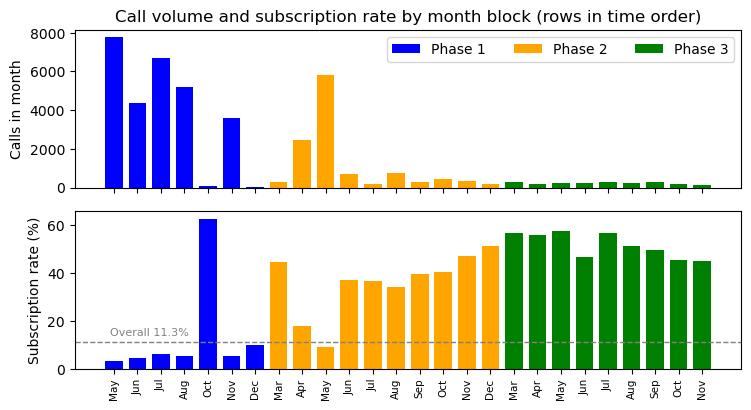

In [12]:
# Figure 1: call volume and subscription rate for each month block, coloured by phase
phase_col = {1: "blue", 2: "orange", 3: "green"}
xs = np.arange(len(per))
fig, axes = plt.subplots(2, 1, figsize=(8.6, 4.4), sharex=True, gridspec_kw={"hspace": 0.15})
for ph in [1, 2, 3]:
    m = per["phase"].values == ph
    axes[0].bar(xs[m], per["calls"].values[m], color=phase_col[ph], width=0.75, label=f"Phase {ph}")
    axes[1].bar(xs[m], per["rate"].values[m] * 100, color=phase_col[ph], width=0.75)
axes[0].set_ylabel("Calls in month")
axes[1].set_ylabel("Subscription rate (%)")
axes[1].axhline(df["target"].mean() * 100, color="gray", linestyle="--", linewidth=1)
axes[1].text(1.5, df["target"].mean() * 100 + 2.5, f"Overall {df['target'].mean():.1%}", ha="center", fontsize=8, color="gray")
axes[1].set_xticks(xs); axes[1].set_xticklabels(per["month"].str.title(), rotation=90, fontsize=7.5)
axes[0].legend(loc="upper right", ncol=3)
axes[0].set_title("Call volume and subscription rate by month block (rows in time order)")
plt.show()

## 4. Train/test split
80/20 split, stratified on the target. Tuning and CV only use the training set.

In [13]:
train, test = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=SEED)
print("Train:", train.shape, round(train.target.mean(), 4), "| Test:", test.shape, round(test.target.mean(), 4))

Train: (32934, 29) 0.1126 | Test: (8234, 29) 0.1126


## 5. Logistic regression (MLE)
The target is binary, so I use logistic regression fitted by maximum likelihood (`statsmodels`). I add the predictors in blocks (M1 to M4), then try two interactions (M5, M6), and compare the models with LRT, AIC and BIC.

In [14]:
J = 'C(job, Treatment("admin."))'
E = 'C(edu, Treatment("university.degree"))'
A = 'C(age_grp, Treatment("35-44"))'
P = 'C(poutcome, Treatment("nonexistent"))'
M = 'C(month, Treatment("may"))'
forms = {}
forms["M1 customer profile"] = f"target ~ {A} + {J} + C(marital) + {E} + default_unk"
forms["M2 + contact history"] = forms["M1 customer profile"] + f" + C(contact) + {P} + log2_campaign"
forms["M3 + economy"] = forms["M2 + contact history"] + " + nr_employed + cpi + cci"
forms["M4 + timing"] = forms["M3 + economy"] + f" + {M} + C(day_of_week)"
forms["M4 using euribor3m"] = forms["M4 + timing"].replace("nr_employed", "euribor3m")
forms["M5 + contact x previous outcome"] = forms["M4 + timing"] + f" + C(contact):{P}"
forms["M6 + contact x age group"] = forms["M4 + timing"] + f" + C(contact):{A}"
forms["M4 without age"] = forms["M4 + timing"].replace(f"{A} + ", "")
forms["M4 with linear age"] = forms["M4 + timing"].replace(A, "age")
forms["M4 with age + age^2"] = forms["M4 + timing"].replace(A, "age + I(age**2)")

fits = {k: smf.logit(f, data=train).fit(disp=0, maxiter=300) for k, f in forms.items()}
sel = pd.DataFrame({k: {"parameters": int(r.df_model) + 1, "log_lik": r.llf, "AIC": r.aic, "BIC": r.bic,
                        "McFadden_R2": r.prsquared} for k, r in fits.items()}).T.round(3)

def lrt(small, big):
    stat = 2 * (fits[big].llf - fits[small].llf)
    ddf = fits[big].df_model - fits[small].df_model
    return stat, int(ddf), stats.chi2.sf(stat, ddf)

lrt_rows = []
for s_, b_ in [("M1 customer profile", "M2 + contact history"), ("M2 + contact history", "M3 + economy"),
               ("M3 + economy", "M4 + timing"), ("M4 + timing", "M5 + contact x previous outcome"),
               ("M4 + timing", "M6 + contact x age group"), ("M4 without age", "M4 + timing"),
               ("M4 with linear age", "M4 with age + age^2")]:
    st, dd, pv = lrt(s_, b_)
    lrt_rows.append({"comparison": f"{s_}  ->  {b_}", "LR_chi2": round(st, 1), "df": dd, "p_value": pv})
lrt_tab = pd.DataFrame(lrt_rows)
print(sel[["parameters", "AIC", "BIC", "McFadden_R2"]])
lrt_tab

                                 parameters        AIC        BIC  McFadden_R2
M1 customer profile                    27.0  21961.224  22188.085        0.055
M2 + contact history                   31.0  20142.459  20402.929        0.134
M3 + economy                           34.0  18816.378  19102.054        0.191
M4 + timing                            47.0  18484.411  18879.318        0.207
M4 using euribor3m                     47.0  18504.357  18899.263        0.206
M5 + contact x previous outcome        49.0  18488.288  18899.999        0.207
M6 + contact x age group               52.0  18487.142  18924.060        0.207
M4 without age                         42.0  18488.023  18840.918        0.206
M4 with linear age                     43.0  18489.937  18851.234        0.206
M4 with age + age^2                    44.0  18478.515  18848.215        0.207


,comparison,LR_chi2,df,p_value
0,M1 customer profile -> M2 + contact history,1826.8,4,0.000000e+00
1,M2 + contact history -> M3 + economy,1332.1,3,1.609614e-288
2,M3 + economy -> M4 + timing,358.0,13,1.634414e-68
3,M4 + timing -> M5 + contact x previous outcome,0.1,2,9.400390e-01
4,M4 + timing -> M6 + contact x age group,7.3,5,2.013836e-01
5,M4 without age -> M4 + timing,13.6,5,1.827740e-02
6,M4 with linear age -> M4 with age + age^2,13.4,1,2.486833e-04


Result: every block improves the fit (LRT p < 0.001). `nr_employed` gives about 20 points lower AIC than `euribor3m`, so I use it. The two interactions are not significant (p = 0.94 and 0.20) and BIC goes up, so the final model is M4.

Age: age + age² has a slightly lower AIC (about 6), but I keep the 6 age groups because their odds ratios can be read as segments, which is what the marketing question needs.

In [15]:
final_formula = forms["M4 + timing"]
logit_fit = fits["M4 + timing"]
print(logit_fit.summary2())

                                                Results: Logit
Model:                             Logit                           Method:                          MLE       
Dependent Variable:                target                          Pseudo R-squared:                0.207     
Date:                              2026-11-01 22:11                AIC:                             18484.4115
No. Observations:                  32934                           BIC:                             18879.3177
Df Model:                          46                              Log-Likelihood:                  -9195.2   
Df Residuals:                      32887                           LL-Null:                         -11593.   
Converged:                         1.0000                          LLR p-value:                     0.0000    
No. Iterations:                    8.0000                          Scale:                           1.0000    
-------------------------------------------------

### 5.1 Assumption checks
- Independence: one row per customer contact, duplicates removed.
- Multicollinearity: VIF of the final design matrix (below).
- Linearity in the logit: age groups and log2(campaign).
- Sample size: about 3,700 subscribers in the training set for 47 parameters.

In [16]:
Xd = pd.DataFrame(logit_fit.model.exog, columns=logit_fit.model.exog_names)
vif_design = pd.Series({c: variance_inflation_factor(Xd.values, i) for i, c in enumerate(Xd.columns) if c != "Intercept"}).round(2)
print("Largest VIFs in the final design matrix:")
print(vif_design.sort_values(ascending=False).head(8))
print("Events in training set:", int(train.target.sum()), "| parameters:", int(logit_fit.df_model) + 1)

Largest VIFs in the final design matrix:
C(contact)[T.telephone]                       3.30
nr_employed                                   3.18
C(marital)[T.single]                          2.90
C(month, Treatment("may"))[T.aug]             2.89
cpi                                           2.84
C(marital)[T.married]                         2.61
C(job, Treatment("admin."))[T.blue-collar]    2.43
C(month, Treatment("may"))[T.jul]             2.33
dtype: float64
Events in training set: 3710 | parameters: 47


### 5.2 Odds ratios with 95% confidence intervals

In [17]:
or_tab = pd.DataFrame({"coef": logit_fit.params, "OR": np.exp(logit_fit.params),
                       "CI_low": np.exp(logit_fit.conf_int()[0]), "CI_high": np.exp(logit_fit.conf_int()[1]),
                       "p_value": logit_fit.pvalues})
def clean_name(n):
    for a, b in [('C(age_grp, Treatment("35-44"))[T.', "Age "), ('C(job, Treatment("admin."))[T.', "Job: "),
                 ('C(edu, Treatment("university.degree"))[T.', "Education: "), ('C(poutcome, Treatment("nonexistent"))[T.', "Previous outcome: "),
                 ('C(month, Treatment("may"))[T.', "Month: "), ("C(day_of_week)[T.", "Day: "), ("C(contact)[T.", "Contact: "),
                 ("C(marital)[T.", "Marital: "), ("]", "")]:
        n = n.replace(a, b)
    return n
or_tab.index = [clean_name(i) for i in or_tab.index]
or_tab = or_tab.drop(index="Intercept")
or_tab.round(3)

,coef,OR,CI_low,CI_high,p_value
Age 17-24,0.264,1.302,1.034,1.639,0.025
Age 25-34,0.126,1.134,1.023,1.258,0.017
Age 45-54,0.090,1.094,0.972,1.231,0.135
Age 55-64,0.165,1.179,1.004,1.386,0.045
Age 65+,0.392,1.479,1.112,1.968,0.007
Job: blue-collar,-0.126,0.881,0.758,1.024,0.100
Job: entrepreneur,0.007,1.007,0.799,1.269,0.955
Job: housemaid,-0.076,0.927,0.701,1.225,0.592
Job: management,-0.022,0.978,0.830,1.152,0.788
Job: retired,0.157,1.170,0.928,1.476,0.185


In [18]:
# Odds ratios for scaled economic terms (per 100 fewer employed; per 1 point of the index)
econ = pd.DataFrame({
    "nr_employed (per 100 lower)": np.exp(-100 * logit_fit.params["nr_employed"]),
    "cpi (per 1 point higher)": np.exp(logit_fit.params["cpi"]),
    "cci (per 1 point higher)": np.exp(logit_fit.params["cci"]),
}, index=["OR"]).T
econ["CI_low"] = [np.exp(-100 * logit_fit.conf_int().loc["nr_employed", 1]), np.exp(logit_fit.conf_int().loc["cpi", 0]), np.exp(logit_fit.conf_int().loc["cci", 0])]
econ["CI_high"] = [np.exp(-100 * logit_fit.conf_int().loc["nr_employed", 0]), np.exp(logit_fit.conf_int().loc["cpi", 1]), np.exp(logit_fit.conf_int().loc["cci", 1])]
econ.round(3)

,OR,CI_low,CI_high
nr_employed (per 100 lower),2.869,2.685,3.066
cpi (per 1 point higher),0.982,0.904,1.066
cci (per 1 point higher),1.020,1.009,1.030


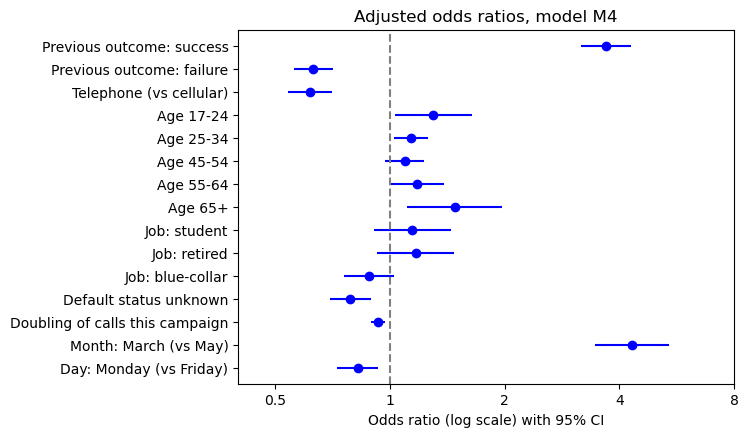

In [19]:
# Figure 4: odds ratios with 95% CI
keep = ["Previous outcome: success", "Previous outcome: failure", "Contact: telephone", "Age 17-24", "Age 25-34",
        "Age 45-54", "Age 55-64", "Age 65+", "Job: student", "Job: retired", "Job: blue-collar", "default_unk",
        "log2_campaign", "Month: mar", "Day: mon"]
labels = {"default_unk": "Default status unknown", "log2_campaign": "Doubling of calls this campaign",
          "Contact: telephone": "Telephone (vs cellular)", "Month: mar": "Month: March (vs May)",
          "Day: mon": "Day: Monday (vs Friday)"}
fp = or_tab.loc[keep].iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
y = np.arange(len(fp))
ax.hlines(y, fp["CI_low"], fp["CI_high"], color="blue")
ax.plot(fp["OR"], y, "o", color="blue")
ax.axvline(1, color="gray", linestyle="--")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xlim(0.4, 8)
ax.set_xticks([0.5, 1, 2, 4, 8]); ax.set_xticklabels(["0.5", "1", "2", "4", "8"])
ax.set_yticks(y); ax.set_yticklabels([labels.get(i, i) for i in fp.index])
ax.set_xlabel("Odds ratio (log scale) with 95% CI")
ax.set_title("Adjusted odds ratios, model M4")
plt.show()

### 5.3 Why a previous failure has an odds ratio below 1
Previous failures subscribe at 14.2% in the raw data, above the 8.8% of never-contacted customers, yet the adjusted odds ratio is 0.63. Most previous failures were called in phases 2 and 3, when the overall rate was much higher. Once the model adjusts for the economic and month variables, the raw advantage disappears.

In [20]:
po_rate = df.groupby("poutcome")["target"].agg(["size", "mean"]).round(3)
print("Raw subscription rate by previous outcome:\n", po_rate)
fail_phase = df.loc[df["poutcome"] == "failure", "phase"].value_counts(normalize=True).sort_index()
print("Share of previous failures by phase:", fail_phase.round(3).to_dict())
print(f"Previous failures called in phases 2 and 3: {fail_phase.loc[[2, 3]].sum():.1%}")
print("Subscription rate by phase:", df.groupby("phase")["target"].mean().round(3).to_dict())

Raw subscription rate by previous outcome:
               size   mean
poutcome                 
failure       4250  0.142
nonexistent  35547  0.088
success       1371  0.651
Share of previous failures by phase: {1: 0.164, 2: 0.703, 3: 0.133}
Previous failures called in phases 2 and 3: 83.6%
Subscription rate by phase: {1: 0.048, 2: 0.195, 3: 0.521}


## 6. Non-parametric models
KNN, decision tree and gradient boosting, using the same predictors as the logistic model (raw `age` and `campaign`, because these models can learn curves themselves). Each one is tuned with 5-fold stratified CV on the training set, scored by ROC-AUC because the goal is to rank customers. Gradient boosting uses early stopping (stop after 30 rounds with no improvement, max 1,000 trees). I did not resample for the class imbalance; the threshold is tuned later instead.

In [21]:
CAT = ["job", "marital", "edu", "default_unk", "contact", "month", "day_of_week", "poutcome"]
NUM = ["age", "campaign", "nr_employed", "cpi", "cci"]
CAT_LOGIT = ["age_grp", "job", "marital", "edu", "contact", "month", "day_of_week", "poutcome"]
NUM_LOGIT = ["default_unk", "log2_campaign", "nr_employed", "cpi", "cci"]
Xtr, Xte, ytr, yte = train, test, train["target"].values, test["target"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def ohe(drop=None):
    return OneHotEncoder(handle_unknown="ignore", drop=drop, sparse_output=False)

pipes = {
    "Logistic regression": Pipeline([("pre", ColumnTransformer([("c", ohe("first"), CAT_LOGIT), ("n", StandardScaler(), NUM_LOGIT)])),
                                     ("m", LogisticRegression(penalty=None, max_iter=5000))]),
    "KNN": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", StandardScaler(), NUM)])),
                     ("m", KNeighborsClassifier())]),
    "Decision tree": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", "passthrough", NUM)])),
                               ("m", DecisionTreeClassifier(random_state=SEED))]),
    "Gradient boosting": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT), ("n", "passthrough", NUM)])),
                                   ("m", HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                                                        n_iter_no_change=30, random_state=SEED))]),
}
grids = {
    "Logistic regression": {},
    "KNN": {"m__n_neighbors": [100, 200, 400, 800, 1600], "m__weights": ["uniform", "distance"]},
    "Decision tree": {"m__max_depth": [4, 6, 8, 10], "m__min_samples_leaf": [50, 100, 200, 400]},
    "Gradient boosting": {"m__learning_rate": [0.05, 0.1], "m__max_depth": [2, 3, 5],
                          "m__min_samples_leaf": [100, 300, 1000], "m__l2_regularization": [1.0, 10.0, 30.0]},
}
best = {}
tuning_rows = []
for name, pipe in pipes.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grids[name] or {"m__max_iter": [5000]}, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    gs.fit(Xtr, ytr)
    best[name] = gs.best_estimator_
    bp = {k.replace("m__", ""): v for k, v in gs.best_params_.items()} if grids[name] else "none (MLE)"
    if name == "Gradient boosting":
        bp["trees_after_early_stopping"] = int(gs.best_estimator_.named_steps["m"].n_iter_)
    scores = gs.cv_results_["mean_test_score"]
    tuning_rows.append({"model": name, "grid_size": len(gs.cv_results_["params"]), "best_params": bp,
                        "cv_auc_best": round(gs.best_score_, 4), "cv_auc_worst_in_grid": round(scores.min(), 4),
                        "seconds": round(time.time() - t0, 1)})
tuning = pd.DataFrame(tuning_rows)
tuning

,model,grid_size,best_params,cv_auc_best,cv_auc_worst_in_grid,seconds
0,Logistic regression,1,none (MLE),0.7839,0.7839,4.9
1,KNN,10,"{'n_neighbors': 800, 'weights': 'uniform'}",0.7827,0.7502,38.5
2,Decision tree,16,"{'max_depth': 6, 'min_samples_leaf': 100}",0.7798,0.7742,4.5
3,Gradient boosting,54,"{'l2_regularization': 30.0, 'learning_rate': 0...",0.7916,0.7870,149.3


## 7. Model comparison
### 7.1 CV metrics on the training set
Out-of-fold ROC-AUC, PR-AUC and Brier score from the same 5 folds. The F1-best threshold is picked here and then used on the test set.

In [22]:
def fold_scores(model):
    aucs, aps, briers = [], [], []
    oof = np.zeros(len(ytr))
    for tr_i, va_i in cv.split(Xtr, ytr):
        m = clone_fit(model, Xtr.iloc[tr_i], ytr[tr_i])
        p = m.predict_proba(Xtr.iloc[va_i])[:, 1]
        oof[va_i] = p
        aucs.append(roc_auc_score(ytr[va_i], p)); aps.append(average_precision_score(ytr[va_i], p)); briers.append(brier_score_loss(ytr[va_i], p))
    return np.array(aucs), np.array(aps), np.array(briers), oof

def clone_fit(model, X, y):
    m = clone(model); m.fit(X, y); return m

def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[np.argmax(f1[:-1])]

cv_rows, oof_preds, thresholds = [], {}, {}
for name, model in best.items():
    aucs, aps, briers, oof = fold_scores(model)
    oof_preds[name] = oof
    thresholds[name] = best_threshold(ytr, oof)
    cv_rows.append({"model": name, "CV ROC-AUC": f"{aucs.mean():.3f} ({aucs.std():.3f})",
                    "CV PR-AUC": f"{aps.mean():.3f} ({aps.std():.3f})", "CV Brier": f"{briers.mean():.4f}",
                    "threshold": round(thresholds[name], 3), "auc_mean": aucs.mean(), "auc_folds": aucs})
cv_tab = pd.DataFrame(cv_rows)
cv_tab[["model", "CV ROC-AUC", "CV PR-AUC", "CV Brier", "threshold"]]

,model,CV ROC-AUC,CV PR-AUC,CV Brier,threshold
0,Logistic regression,0.784 (0.011),0.439 (0.017),0.0796,0.199
1,KNN,0.783 (0.008),0.407 (0.018),0.0824,0.168
2,Decision tree,0.780 (0.010),0.427 (0.021),0.0790,0.210
3,Gradient boosting,0.792 (0.008),0.455 (0.022),0.0783,0.211


In [23]:
# Paired comparison of fold AUCs (same folds for every model)
auc_folds = {r["model"]: r["auc_folds"] for r in cv_rows}
for other in ["KNN", "Decision tree", "Gradient boosting"]:
    d = auc_folds[other] - auc_folds["Logistic regression"]
    t_stat, p_val = stats.ttest_rel(auc_folds[other], auc_folds["Logistic regression"])
    print(f"{other:18s} minus logistic: mean AUC difference = {d.mean():+.4f}, paired t = {t_stat:.2f}, p = {p_val:.3f}")

KNN                minus logistic: mean AUC difference = -0.0012, paired t = -0.61, p = 0.575
Decision tree      minus logistic: mean AUC difference = -0.0041, paired t = -1.55, p = 0.196
Gradient boosting  minus logistic: mean AUC difference = +0.0077, paired t = 4.31, p = 0.013


### 7.2 Hold-out test set

In [24]:
test_pred = {name: m.predict_proba(Xte)[:, 1] for name, m in best.items()}
def top_capture(y, p, frac):
    k = int(np.ceil(frac * len(p)))
    idx = np.argsort(-p)[:k]
    return y[idx].sum() / y.sum(), y[idx].mean()
test_rows = []
for name, p in test_pred.items():
    yhat = (p >= thresholds[name]).astype(int)
    cap20, prec20 = top_capture(yte, p, 0.2)
    test_rows.append({"model": name, "Test ROC-AUC": roc_auc_score(yte, p), "Test PR-AUC": average_precision_score(yte, p),
                      "Brier": brier_score_loss(yte, p), "Precision": precision_score(yte, yhat), "Recall": recall_score(yte, yhat),
                      "F1": f1_score(yte, yhat), "Top-20% capture": cap20, "Top-20% hit rate": prec20})
test_tab = pd.DataFrame(test_rows).set_index("model").round(3)
test_tab

,Test ROC-AUC,Test PR-AUC,Brier,Precision,Recall,F1,Top-20% capture,Top-20% hit rate
model,,,,,,,,
Logistic regression,0.800,0.462,0.077,0.448,0.586,0.508,0.648,0.365
KNN,0.799,0.434,0.080,0.448,0.578,0.505,0.652,0.367
Decision tree,0.797,0.450,0.076,0.464,0.586,0.518,0.635,0.358
Gradient boosting,0.807,0.477,0.076,0.472,0.591,0.525,0.660,0.372


### 7.3 Time-based test
The random split mixes all periods. To see how the models would do on a later campaign, I train on phases 1-2 and test on phase 3 (n = 2,054). In phase 3 the subscription rate is 52% (vs 9% before) and `nr_employed` is lower than anything in training, so I also try LR and GB with only the customer and contact variables.

In [25]:
early, late = df[df["phase"] < 3], df[df["phase"] == 3]
print(f"Train phases 1-2: n = {len(early)}, base rate = {early.target.mean():.3f}, nr_employed {early.nr_employed.min()}-{early.nr_employed.max()}")
print(f"Test phase 3:     n = {len(late)}, base rate = {late.target.mean():.3f}, nr_employed {late.nr_employed.min()}-{late.nr_employed.max()}")
temporal = {}
for name, model in best.items():
    m = clone_fit(model, early, early["target"].values)
    temporal[name] = roc_auc_score(late["target"].values, m.predict_proba(late)[:, 1])
temporal = pd.Series(temporal, name="Phase-3 ROC-AUC").round(3)

CAT_CUST = ["age_grp", "job", "marital", "edu", "contact", "day_of_week", "poutcome"]
NUM_CUST = ["default_unk", "log2_campaign"]
cust_models = {
    "Logistic regression (customer and contact only)": Pipeline([("pre", ColumnTransformer([("c", ohe("first"), CAT_CUST), ("n", StandardScaler(), NUM_CUST)])),
                                                         ("m", LogisticRegression(penalty=None, max_iter=5000))]),
    "Gradient boosting (customer and contact only)": Pipeline([("pre", ColumnTransformer([("c", ohe(), CAT_CUST), ("n", "passthrough", NUM_CUST)])),
                                                       ("m", clone(best["Gradient boosting"].named_steps["m"]))]),
}
temporal_cust = {}
for name, m in cust_models.items():
    m.fit(early, early["target"].values)
    temporal_cust[name] = round(roc_auc_score(late["target"].values, m.predict_proba(late)[:, 1]), 3)
temporal_all = pd.concat([temporal, pd.Series(temporal_cust, name="Phase-3 ROC-AUC")])
temporal_all

Train phases 1-2: n = 39114, base rate = 0.091, nr_employed 5017.5-5228.1
Test phase 3:     n = 2054, base rate = 0.521, nr_employed 4963.6-5008.7


Logistic regression                                0.674
KNN                                                0.602
Decision tree                                      0.697
Gradient boosting                                  0.647
Logistic regression (customer and contact only)    0.697
Gradient boosting (customer and contact only)      0.698
Name: Phase-3 ROC-AUC, dtype: float64

In [26]:
summary_tab = pd.DataFrame({
    "CV ROC-AUC (sd)": cv_tab.set_index("model")["CV ROC-AUC"],
    "CV PR-AUC (sd)": cv_tab.set_index("model")["CV PR-AUC"],
    "Test ROC-AUC": test_tab["Test ROC-AUC"], "Test PR-AUC": test_tab["Test PR-AUC"],
    "Precision": test_tab["Precision"], "Recall": test_tab["Recall"], "F1": test_tab["F1"],
    "Top-20% capture": test_tab["Top-20% capture"], "Phase-3 ROC-AUC": temporal,
})
summary_tab

,CV ROC-AUC (sd),CV PR-AUC (sd),Test ROC-AUC,Test PR-AUC,Precision,Recall,F1,Top-20% capture,Phase-3 ROC-AUC
Logistic regression,0.784 (0.011),0.439 (0.017),0.800,0.462,0.448,0.586,0.508,0.648,0.674
KNN,0.783 (0.008),0.407 (0.018),0.799,0.434,0.448,0.578,0.505,0.652,0.602
Decision tree,0.780 (0.010),0.427 (0.021),0.797,0.450,0.464,0.586,0.518,0.635,0.697
Gradient boosting,0.792 (0.008),0.455 (0.022),0.807,0.477,0.472,0.591,0.525,0.660,0.647


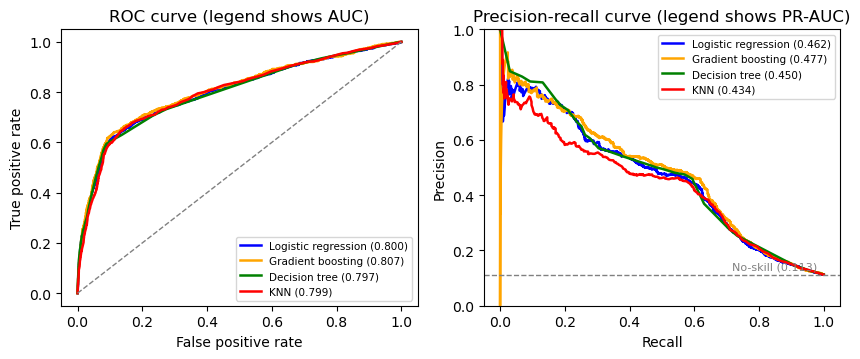

In [27]:
# Figure: ROC and precision-recall curves on the test set
colors = {"Logistic regression": "blue", "Gradient boosting": "orange", "Decision tree": "green", "KNN": "red"}
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.7))
for name in ["Logistic regression", "Gradient boosting", "Decision tree", "KNN"]:
    p = test_pred[name]
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(yte, p):.3f})", linewidth=1.8)
    pr, rc, _ = precision_recall_curve(yte, p)
    axes[1].plot(rc, pr, color=colors[name], label=f"{name} ({average_precision_score(yte, p):.3f})", linewidth=1.8)
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
axes[1].axhline(yte.mean(), color="gray", linestyle="--", linewidth=1)
axes[1].text(0.98, yte.mean() + 0.02, f"No-skill ({yte.mean():.3f})", ha="right", fontsize=8, color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1))
axes[0].set_title("ROC curve (legend shows AUC)")
axes[1].set_title("Precision-recall curve (legend shows PR-AUC)")
axes[0].legend(loc="lower right", fontsize=7.5); axes[1].legend(loc="upper right", fontsize=7.5)
fig.tight_layout()
plt.show()

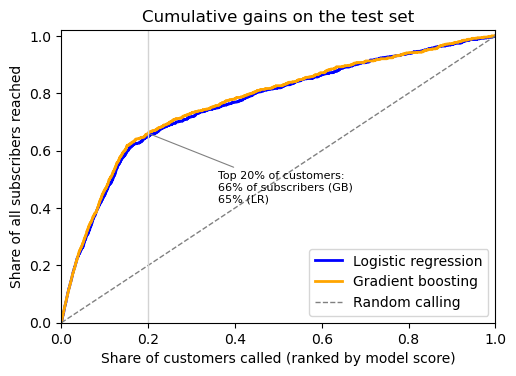

{'top 10%': {'Logistic regression': np.float64(0.446), 'Gradient boosting': np.float64(0.464)}, 'top 20%': {'Logistic regression': np.float64(0.648), 'Gradient boosting': np.float64(0.66)}, 'top 30%': {'Logistic regression': np.float64(0.718), 'Gradient boosting': np.float64(0.731)}, 'top 50%': {'Logistic regression': np.float64(0.819), 'Gradient boosting': np.float64(0.826)}}


In [28]:
# Figure: cumulative gains chart on the test set
fig, ax = plt.subplots(figsize=(5.6, 3.8))
for name in ["Logistic regression", "Gradient boosting"]:
    order = np.argsort(-test_pred[name])
    cum = np.concatenate([[0], np.cumsum(yte[order]) / yte.sum()])
    xs = np.arange(len(cum)) / len(yte)
    ax.plot(xs, cum, color=colors[name], label=name, linewidth=2)
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Random calling")
cap_lr, _ = top_capture(yte, test_pred["Logistic regression"], 0.2)
cap_gb, _ = top_capture(yte, test_pred["Gradient boosting"], 0.2)
ax.axvline(0.2, color="lightgray", linewidth=1)
ax.annotate(f"Top 20% of customers:\n{cap_gb:.0%} of subscribers (GB)\n{cap_lr:.0%} (LR)", xy=(0.2, cap_gb), xytext=(0.36, 0.42),
            fontsize=8, color="black", arrowprops=dict(arrowstyle="-", color="gray", linewidth=0.8))
ax.set(xlabel="Share of customers called (ranked by model score)", ylabel="Share of all subscribers reached",
       xlim=(0, 1), ylim=(0, 1.02))
ax.set_title("Cumulative gains on the test set")
ax.legend(loc="lower right")
plt.show()
print({f"top {int(f*100)}%": {n: round(top_capture(yte, test_pred[n], f)[0], 3) for n in ["Logistic regression", "Gradient boosting"]} for f in [0.1, 0.2, 0.3, 0.5]})

## 8. Interpreting the non-parametric models
### 8.1 Permutation importance (gradient boosting, test set)
Shuffle one variable at a time and see how much the test AUC drops.

In [29]:
gb = best["Gradient boosting"]
feat_cols = CAT + NUM
pi = permutation_importance(gb, Xte[feat_cols], yte, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=feat_cols).sort_values("importance", ascending=False)
imp.round(4)

,importance,sd
nr_employed,0.1174,0.0067
contact,0.0105,0.0025
cpi,0.0081,0.0025
poutcome,0.0081,0.0011
cci,0.0055,0.0011
day_of_week,0.0049,0.0007
month,0.0043,0.0017
campaign,0.0036,0.0019
age,0.0022,0.0018
default_unk,0.0019,0.0007


Partial dependence at ages 20, 40, 70: [0.129 0.102 0.137]


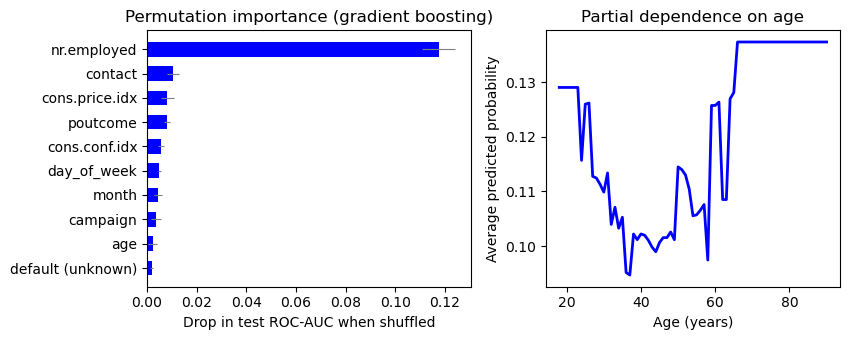

In [30]:
# partial dependence on age: give everyone in a 5,000-row sample the same age, then average the predictions
pd_sample = Xtr[feat_cols].sample(5000, random_state=SEED)
age_grid = np.arange(18, 91, 1.0)
age_pd = []
for a_val in age_grid:
    tmp_x = pd_sample.copy()
    tmp_x["age"] = a_val
    age_pd.append(gb.predict_proba(tmp_x)[:, 1].mean())
age_pd = np.array(age_pd)
print("Partial dependence at ages 20, 40, 70:", age_pd[[2, 22, 52]].round(3))

nice = {"nr_employed": "nr.employed", "cpi": "cons.price.idx", "cci": "cons.conf.idx", "edu": "education",
        "default_unk": "default (unknown)", "day_of_week": "day_of_week"}
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.5), gridspec_kw={"width_ratios": [1.1, 1]})
top = imp.head(10).iloc[::-1]
axes[0].barh([nice.get(i, i) for i in top.index], top["importance"], color="blue", height=0.6, xerr=top["sd"],
             error_kw=dict(ecolor="gray", elinewidth=0.8))
axes[0].set_xlabel("Drop in test ROC-AUC when shuffled")
axes[0].set_title("Permutation importance (gradient boosting)")
axes[1].plot(age_grid, age_pd, color="blue", linewidth=2)
axes[1].set(xlabel="Age (years)", ylabel="Average predicted probability")
axes[1].set_title("Partial dependence on age")
fig.tight_layout()
plt.show()

### 8.2 Decision tree segments
The tuned tree is too deep to read, so I fit a small depth-3 tree (min 300 customers per leaf) just to describe the main segments.

In [31]:
tree = best["Decision tree"]
print("Tuned tree depth:", tree.named_steps["m"].get_depth(), "| leaves:", tree.named_steps["m"].get_n_leaves())

# small tree on the same one-hot encoded training data
pre_tree = tree.named_steps["pre"]
Xtr_t = pre_tree.transform(Xtr)
feat_names = [n.split("__", 1)[1] for n in pre_tree.get_feature_names_out()]
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=300, random_state=SEED).fit(Xtr_t, ytr)
print(export_text(small_tree, feature_names=feat_names))

# customers and subscription rate in each leaf
leaf = small_tree.apply(Xtr_t)
segments = pd.DataFrame({"leaf": leaf, "y": ytr}).groupby("leaf")["y"].agg(customers="size", rate="mean")
segments["share_customers"] = segments["customers"] / len(ytr)
segments["share_subscribers"] = segments["customers"] * segments["rate"] / ytr.sum()
segments.sort_values("rate", ascending=False).round(3)

Tuned tree depth: 6 | leaves: 36
|--- nr_employed <= 5087.65
|   |--- poutcome_success <= 0.50
|   |   |--- contact_cellular <= 0.50
|   |   |   |--- class: 0
|   |   |--- contact_cellular >  0.50
|   |   |   |--- class: 0
|   |--- poutcome_success >  0.50
|   |   |--- cpi <= 93.17
|   |   |   |--- class: 1
|   |   |--- cpi >  93.17
|   |   |   |--- class: 1
|--- nr_employed >  5087.65
|   |--- cci <= -46.65
|   |   |--- poutcome_failure <= 0.50
|   |   |   |--- class: 0
|   |   |--- poutcome_failure >  0.50
|   |   |   |--- class: 0
|   |--- cci >  -46.65
|   |   |--- cpi <= 93.96
|   |   |   |--- class: 0
|   |   |--- cpi >  93.96
|   |   |   |--- class: 0



,customers,rate,share_customers,share_subscribers
leaf,,,,
7,523,0.767,0.016,0.108
6,380,0.642,0.012,0.066
4,2602,0.385,0.079,0.270
10,1673,0.236,0.051,0.106
3,482,0.226,0.015,0.029
11,496,0.111,0.015,0.015
13,17096,0.068,0.519,0.313
14,9682,0.036,0.294,0.093


## 9. Bayesian estimation
posterior ∝ likelihood × prior. MLE gives one best value, while the Bayesian approach gives a whole distribution, and a 95% credible interval can be read as a probability for the parameter. With a lot of data and a weak prior, the two should agree.

### 9.1 Beta-Binomial model for segment rates
Each segment rate gets a Beta prior and the number of subscribers is Binomial, so the posterior is Beta(a + subscribers, b + non-subscribers). Main prior: Beta(2.25, 17.75), centred on the overall rate (11.3%) with the weight of 20 customers, so very small groups (e.g. illiterate, n = 18) are pulled toward the average. I also show a uniform Beta(1, 1) prior as a check.

In [32]:
p0 = df["target"].mean()
a0, b0 = 20 * p0, 20 * (1 - p0)
print(f"Main prior: Beta({a0:.2f}, {b0:.2f})")
def bayes_rates(col, frame=df):
    g = frame.groupby(col)["target"].agg(["size", "sum"])
    out = []
    for lvl, (n, k) in g.iterrows():
        post = stats.beta(a0 + k, b0 + n - k)
        flat = stats.beta(1 + k, 1 + n - k)
        out.append({"variable": col, "segment": lvl, "n": int(n), "observed": k / n, "posterior_mean": post.mean(),
                    "CrI_low": post.ppf(0.025), "CrI_high": post.ppf(0.975), "P(rate > overall)": 1 - post.cdf(p0),
                    "uniform_prior_CrI": f"{flat.ppf(0.025):.3f}-{flat.ppf(0.975):.3f}"})
    return pd.DataFrame(out)
bayes = pd.concat([bayes_rates(c) for c in ["age_grp", "job", "education", "poutcome", "contact"]], ignore_index=True)
bayes.round(3)

Main prior: Beta(2.25, 17.75)


,variable,segment,n,observed,posterior_mean,CrI_low,CrI_high,P(rate > overall),uniform_prior_CrI
0,age_grp,17-24,1067,0.240,0.238,0.213,0.263,1.000,0.215-0.266
1,age_grp,25-34,13684,0.122,0.122,0.116,0.127,1.000,0.116-0.127
2,age_grp,35-44,13492,0.086,0.087,0.082,0.091,0.000,0.082-0.091
3,age_grp,45-54,8701,0.086,0.086,0.081,0.092,0.000,0.081-0.093
4,age_grp,55-64,3563,0.136,0.135,0.124,0.147,1.000,0.125-0.147
5,age_grp,65+,661,0.474,0.463,0.426,0.500,1.000,0.436-0.512
6,job,admin.,10419,0.130,0.130,0.123,0.136,1.000,0.123-0.136
7,job,blue-collar,9252,0.069,0.069,0.064,0.074,0.000,0.064-0.074
8,job,entrepreneur,1456,0.085,0.086,0.072,0.100,0.000,0.072-0.101
9,job,housemaid,1059,0.100,0.100,0.083,0.119,0.092,0.083-0.120


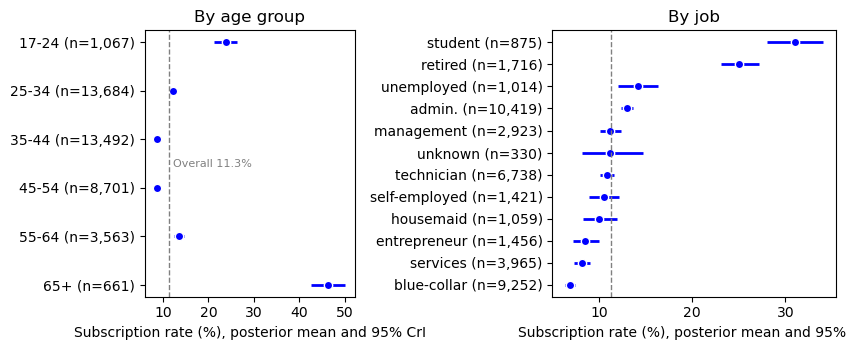

In [33]:
# Figure: posterior subscription rate by age group and job (95% credible intervals)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.6), gridspec_kw={"width_ratios": [1, 1.35]})
for ax, col, order in [(axes[0], "age_grp", AGE_LABELS[::-1]), (axes[1], "job", None)]:
    b = bayes[bayes.variable == col].set_index("segment")
    b = b.loc[order] if order else b.sort_values("posterior_mean")
    yy = np.arange(len(b))
    ax.hlines(yy, b["CrI_low"] * 100, b["CrI_high"] * 100, color="blue", linewidth=2)
    ax.plot(b["posterior_mean"] * 100, yy, "o", color="blue", markersize=6, markeredgecolor="white")
    ax.axvline(p0 * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(yy); ax.set_yticklabels([f"{s} (n={n:,})" for s, n in zip(b.index, b["n"])])
    ax.set_xlabel("Subscription rate (%), posterior mean and 95% CrI")
axes[0].text(p0 * 100 + 1, 2.5, f"Overall {p0:.1%}", fontsize=8, color="gray", va="center")
axes[0].set_title("By age group"); axes[1].set_title("By job")
fig.tight_layout()
plt.show()

### 9.2 Bayesian logistic regression (MCMC)
Same model M4 as Section 5, with a Normal(0, 2.5²) prior on every coefficient. The four numeric predictors are standardised first so the same prior works for all of them. There is no closed-form posterior, so I sample it with MCMC (random-walk Metropolis-Hastings):
1. start near the MLE
2. propose a small random move
3. accept it with probability min(1, posterior ratio), otherwise stay
4. drop the burn-in, keep every 50th draw (thinning), and check the trace, autocorrelation and density plots

The step size uses the MLE covariance scaled by 2.38² / 47 (Gelman et al., 2013).

In [34]:
Xb = pd.DataFrame(logit_fit.model.exog, columns=logit_fit.model.exog_names)
yb = train["target"].values
STD_COLS = ["nr_employed", "cpi", "cci", "log2_campaign"]
mu_b, sd_b = Xb[STD_COLS].mean(), Xb[STD_COLS].std()
Xz_df = Xb.copy()
Xz_df[STD_COLS] = (Xb[STD_COLS] - mu_b) / sd_b
Xz = Xz_df.values
mle_z = sm.Logit(yb, Xz).fit(disp=0)
print("log-likelihood check:", round(mle_z.llf, 3), round(logit_fit.llf, 3))

def log_post(beta, prior_sd):
    eta = Xz @ beta
    return np.sum(yb * eta - np.logaddexp(0, eta)) - 0.5 * np.sum(beta ** 2) / prior_sd ** 2

def metropolis(n_iter, prior_sd, seed):
    rng = np.random.default_rng(seed)
    L = np.linalg.cholesky(np.asarray(mle_z.cov_params()))
    step = 2.38 / np.sqrt(Xz.shape[1])
    beta = np.asarray(mle_z.params) + 3 * L @ rng.standard_normal(Xz.shape[1])   # start a bit away from the MLE
    lp = log_post(beta, prior_sd)
    samples = np.zeros((n_iter, len(beta)))
    n_acc = 0
    for i in range(n_iter):
        prop = beta + step * L @ rng.standard_normal(len(beta))
        lp_prop = log_post(prop, prior_sd)
        if np.log(rng.random()) < lp_prop - lp:
            beta, lp = prop, lp_prop
            n_acc += 1
        samples[i] = beta
    return samples, n_acc / n_iter

n_iter, burn, thin = 60000, 5000, 50
t0 = time.time()
samples, acc = metropolis(n_iter, 2.5, SEED)
print(f"{n_iter} iterations in {time.time() - t0:.0f}s, acceptance rate {acc:.3f}")
kept = samples[burn::thin]
print("draws kept after burn-in and thinning:", len(kept))

log-likelihood check: -9195.206 -9195.206
60000 iterations in 98s, acceptance rate 0.242
draws kept after burn-in and thinning: 1100


### 9.2.1 Convergence plots

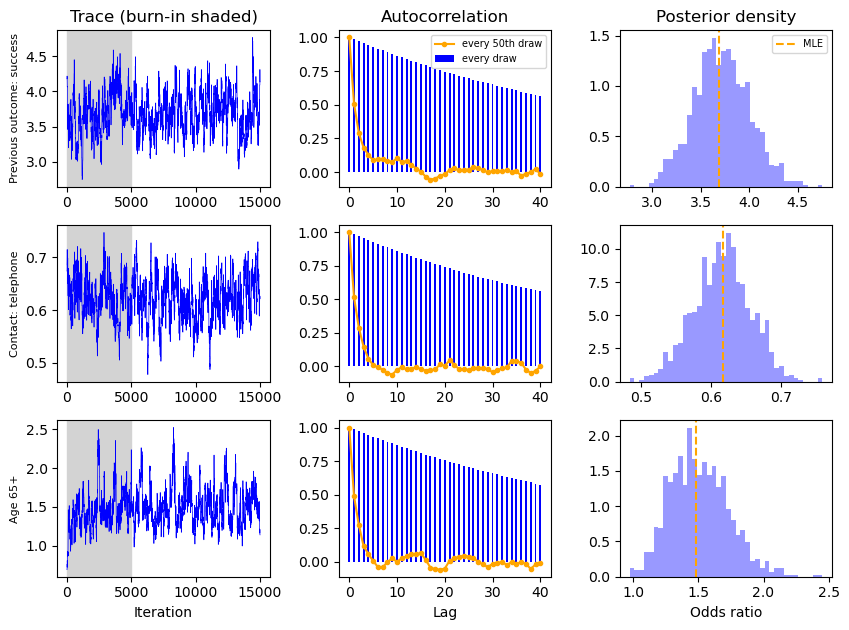

In [35]:
names = list(Xb.columns)
show = [("Previous outcome: success", 'C(poutcome, Treatment("nonexistent"))[T.success]'),
        ("Contact: telephone", "C(contact)[T.telephone]"),
        ("Age 65+", 'C(age_grp, Treatment("35-44"))[T.65+]')]
mle_params, mle_ci = logit_fit.params, logit_fit.conf_int()

def autocorr(x, lags=40):
    s = pd.Series(x)
    return [s.autocorr(k) for k in range(lags + 1)]

# Figure 7: trace, autocorrelation and posterior density (odds ratio scale)
fig, axes = plt.subplots(3, 3, figsize=(8.6, 6.4))
for r, (label, col) in enumerate(show):
    j = names.index(col)
    axes[r, 0].plot(np.exp(samples[:15000, j]), color="blue", linewidth=0.5)
    axes[r, 0].axvspan(0, burn, color="lightgray")
    axes[r, 0].set_ylabel(label, fontsize=8)
    axes[r, 1].bar(range(41), autocorr(samples[burn:, j]), color="blue", width=0.4, label="every draw")
    axes[r, 1].plot(range(41), autocorr(kept[:, j]), "o-", color="orange", markersize=3, label="every 50th draw")
    axes[r, 2].hist(np.exp(kept[:, j]), bins=40, density=True, color="blue", alpha=0.4)
    axes[r, 2].axvline(np.exp(mle_params[col]), color="orange", linestyle="--", label="MLE")
axes[0, 0].set_title("Trace (burn-in shaded)")
axes[0, 1].set_title("Autocorrelation")
axes[0, 2].set_title("Posterior density")
axes[0, 1].legend(fontsize=7)
axes[0, 2].legend(fontsize=7)
axes[2, 0].set_xlabel("Iteration"); axes[2, 1].set_xlabel("Lag"); axes[2, 2].set_xlabel("Odds ratio")
fig.tight_layout()
plt.show()

### 9.2.2 Posterior odds ratios vs MLE

In [36]:
# back to the original units: slopes divided by sd, intercept adjusted for the centring
coef = kept.copy()
for c in STD_COLS:
    coef[:, names.index(c)] = kept[:, names.index(c)] / sd_b[c]
coef[:, names.index("Intercept")] -= sum(coef[:, names.index(c)] * mu_b[c] for c in STD_COLS)

q = np.quantile(coef, [0.025, 0.5, 0.975], axis=0)
cmp_tab = pd.DataFrame({"OR_MLE": np.exp(mle_params.values), "MLE_low": np.exp(mle_ci[0].values), "MLE_high": np.exp(mle_ci[1].values),
                        "OR_Bayes": np.exp(q[1]), "CrI_low": np.exp(q[0]), "CrI_high": np.exp(q[2])},
                       index=[clean_name(n) for n in names]).drop(index="Intercept")
gap = np.abs(coef.mean(axis=0) - mle_params.values) / logit_fit.bse.values
print("largest gap between posterior mean and MLE (in SEs):", round(gap.max(), 2))
diff_sig = ((cmp_tab.CrI_low > 1) | (cmp_tab.CrI_high < 1)) != ((cmp_tab.MLE_low > 1) | (cmp_tab.MLE_high < 1))
print("terms where the CI and the CrI disagree about excluding 1:", list(cmp_tab.index[diff_sig]))
cmp_tab.round(3)

largest gap between posterior mean and MLE (in SEs): 0.11
terms where the CI and the CrI disagree about excluding 1: ['Age 55-64']


,OR_MLE,MLE_low,MLE_high,OR_Bayes,CrI_low,CrI_high
Age 17-24,1.302,1.034,1.639,1.297,1.025,1.625
Age 25-34,1.134,1.023,1.258,1.132,1.022,1.262
Age 45-54,1.094,0.972,1.231,1.091,0.967,1.234
Age 55-64,1.179,1.004,1.386,1.180,0.998,1.377
Age 65+,1.479,1.112,1.968,1.493,1.128,2.002
Job: blue-collar,0.881,0.758,1.024,0.887,0.765,1.020
Job: entrepreneur,1.007,0.799,1.269,1.003,0.801,1.256
Job: housemaid,0.927,0.701,1.225,0.929,0.693,1.214
Job: management,0.978,0.830,1.152,0.973,0.830,1.147
Job: retired,1.170,0.928,1.476,1.174,0.924,1.455


In [37]:
# probabilities we can only get from the posterior
def p_or_above(col, value=1.0):
    return (np.exp(coef[:, names.index(col)]) > value).mean()

print("P(OR previous success > 3) =", round(p_or_above(show[0][1], 3), 3))
print("P(OR age 65+ > 1) =", round(p_or_above(show[2][1]), 3))
print("P(OR age 17-24 > 1) =", round(p_or_above('C(age_grp, Treatment("35-44"))[T.17-24]'), 3))
print("P(OR telephone < 0.7) =", round(1 - p_or_above(show[1][1], 0.7), 3))

P(OR previous success > 3) = 0.997
P(OR age 65+ > 1) = 0.997
P(OR age 17-24 > 1) = 0.983
P(OR telephone < 0.7) = 0.987


### 9.2.3 Tighter prior
Same sampler with a Normal(0, 0.5²) prior. If the data dominate, the results should hardly move.

In [38]:
samples_tight, acc_tight = metropolis(30000, 0.5, SEED + 1)
kept_tight = samples_tight[3000::10].copy()
for c in STD_COLS:
    kept_tight[:, names.index(c)] /= sd_b[c]
shift = np.abs(kept_tight.mean(axis=0) - coef.mean(axis=0)) / logit_fit.bse.values
shift = pd.Series(shift, index=[clean_name(n) for n in names]).drop("Intercept")
print("acceptance rate:", round(acc_tight, 3))
print("largest shift (SEs):", round(shift.max(), 2), "| median:", round(shift.median(), 2))
print(shift.sort_values(ascending=False).head(5).round(2))
print(shift.loc[["Previous outcome: success", "Contact: telephone", "Age 65+", "Age 17-24", "log2_campaign"]].round(2))

acceptance rate: 0.232
largest shift (SEs): 1.11 | median: 0.24
Month: mar    1.11
Month: jul    1.07
Month: aug    1.03
Month: nov    0.95
Month: jun    0.93
dtype: float64
Previous outcome: success    0.45
Contact: telephone           0.60
Age 65+                      0.26
Age 17-24                    0.22
log2_campaign                0.05
dtype: float64


Result: the chain looks stable after the burn-in (acceptance rate 0.24). Autocorrelation is high between consecutive draws but drops a lot after keeping every 50th draw.

The posterior odds ratios are very close to the MLE (largest gap 0.11 SEs), because the training set is large and the prior is weak. Only Age 55-64 changes: its CI just excludes 1, but the CrI just includes 1. The posterior also gives direct probabilities, e.g. P(OR for previous success > 3) = 0.997.

With the tighter prior the largest shift is 1.1 SEs (month effects), and the terms used in the business insights move 0.6 SEs or less. So the MLE results hold, and the Bayesian fit mainly confirms them.

## 10. Business insight calculations

In [39]:
# Insight: contact intensity
camp = df.assign(calls=df["campaign"].clip(upper=6).astype(int).astype(str).replace({"6": "6+"})).groupby("calls")["target"].agg(["size", "mean"]).round(3)
print("Subscription rate by number of calls in this campaign:\n", camp)
share_after3 = (df["campaign"] > 3).mean()
subs_after3 = df.loc[df["campaign"] > 3, "target"].sum() / df["target"].sum()
print(f"Calls beyond the 3rd attempt: {share_after3:.1%} of customers, {subs_after3:.1%} of subscribers")

Subscription rate by number of calls in this campaign:
         size   mean
calls              
1      17629  0.130
2      10566  0.115
3       5339  0.108
4       2650  0.094
5       1599  0.075
6+      3385  0.055
Calls beyond the 3rd attempt: 18.5% of customers, 12.0% of subscribers


In [40]:
# Insight: previous success customers
ps = df[df.poutcome == "success"]
print(f"Previous-success customers: n = {len(ps)} ({len(ps)/len(df):.1%} of base), rate = {ps.target.mean():.1%}, share of all subscribers = {ps.target.sum()/df.target.sum():.1%}")

Previous-success customers: n = 1371 (3.3% of base), rate = 65.1%, share of all subscribers = 19.2%


In [41]:
# Insight: calls saved by targeting with gradient boosting at different coverage levels (test set)
for frac in [0.2, 0.3, 0.5]:
    cap, hit = top_capture(yte, test_pred["Gradient boosting"], frac)
    print(f"Call top {frac:.0%}: reach {cap:.1%} of subscribers, hit rate {hit:.1%} (vs {yte.mean():.1%} calling everyone); calls avoided {1-frac:.0%}")

Call top 20%: reach 66.0% of subscribers, hit rate 37.2% (vs 11.3% calling everyone); calls avoided 80%
Call top 30%: reach 73.1% of subscribers, hit rate 27.4% (vs 11.3% calling everyone); calls avoided 70%
Call top 50%: reach 82.6% of subscribers, hit rate 18.6% (vs 11.3% calling everyone); calls avoided 50%


## 11. Fairness check by age group (used in the ethics section)
Selection rate by age group if we call the top 20% from each model (test set), next to each group's share of customers and its actual subscription rate.

In [42]:
fair_tabs = []
for name in ["Logistic regression", "Gradient boosting"]:
    p_m = test_pred[name]
    sel_flag = p_m >= np.quantile(p_m, 0.8)
    f = pd.DataFrame({"age_grp": test["age_grp"].values, "selected": sel_flag, "y": yte}).groupby("age_grp").agg(
        n=("y", "size"), actual_rate=("y", "mean"), selected_rate=("selected", "mean")).loc[AGE_LABELS]
    f["share_of_customers"] = f["n"] / f["n"].sum()
    f["share_of_call_list"] = f["selected_rate"] * f["n"] / sel_flag.sum()
    f.insert(0, "model", name)
    fair_tabs.append(f)
fair = pd.concat(fair_tabs)
fair.round(3)

,model,n,actual_rate,selected_rate,share_of_customers,share_of_call_list
age_grp,,,,,,
17-24,Logistic regression,182,0.269,0.544,0.022,0.060
25-34,Logistic regression,2757,0.127,0.230,0.335,0.384
35-44,Logistic regression,2709,0.090,0.140,0.329,0.230
45-54,Logistic regression,1759,0.072,0.131,0.214,0.140
55-64,Logistic regression,682,0.135,0.238,0.083,0.098
65+,Logistic regression,145,0.455,0.986,0.018,0.087
17-24,Gradient boosting,182,0.269,0.593,0.022,0.066
25-34,Gradient boosting,2757,0.127,0.234,0.335,0.391
35-44,Gradient boosting,2709,0.090,0.128,0.329,0.210


## 12. Hypothesis summary

In [43]:
o = or_tab
hyp = pd.DataFrame([
    {"hypothesis": "H1: customers under 25 and 65+ have higher odds than 35-44 (adjusted)",
     "test": "Wald z in M4; LRT for the age block",
     "result": f"17-24 OR {o.loc['Age 17-24','OR']:.2f} [{o.loc['Age 17-24','CI_low']:.2f}, {o.loc['Age 17-24','CI_high']:.2f}]; 65+ OR {o.loc['Age 65+','OR']:.2f} [{o.loc['Age 65+','CI_low']:.2f}, {o.loc['Age 65+','CI_high']:.2f}]; age block LRT p = {lrt('M4 without age', 'M4 + timing')[2]:.4f}"},
    {"hypothesis": "H2: previous campaign success is the strongest customer-level predictor",
     "test": "Odds ratios in M4; permutation importance",
     "result": f"Previous success OR {o.loc['Previous outcome: success','OR']:.2f} [{o.loc['Previous outcome: success','CI_low']:.2f}, {o.loc['Previous outcome: success','CI_high']:.2f}], largest customer-level OR; nr_employed dominates overall importance"},
    {"hypothesis": "H3: cellular contact raises the odds, and the channel effect depends on previous outcome",
     "test": "Wald z; LRT for contact x poutcome",
     "result": f"Telephone OR {o.loc['Contact: telephone','OR']:.2f} [{o.loc['Contact: telephone','CI_low']:.2f}, {o.loc['Contact: telephone','CI_high']:.2f}]; interaction LRT p = {lrt('M4 + timing', 'M5 + contact x previous outcome')[2]:.2f} (not supported)"},
    {"hypothesis": "H4: more calls in the same campaign lower the odds",
     "test": "Wald z for log2_campaign",
     "result": f"OR per doubling {o.loc['log2_campaign','OR']:.2f} [{o.loc['log2_campaign','CI_low']:.2f}, {o.loc['log2_campaign','CI_high']:.2f}]"},
    {"hypothesis": "H5: a non-parametric model ranks customers better than logistic regression",
     "test": "Paired t-test on CV fold AUCs; test AUC; phase-3 test",
     "result": f"GB - LR test AUC {test_tab.loc['Gradient boosting', 'Test ROC-AUC'] - test_tab.loc['Logistic regression', 'Test ROC-AUC']:+.3f}; phase-3 AUC GB {temporal['Gradient boosting']:.3f} vs LR {temporal['Logistic regression']:.3f}"},
])
hyp

,hypothesis,test,result
0,H1: customers under 25 and 65+ have higher odd...,Wald z in M4; LRT for the age block,"17-24 OR 1.30 [1.03, 1.64]; 65+ OR 1.48 [1.11,..."
1,H2: previous campaign success is the strongest...,Odds ratios in M4; permutation importance,"Previous success OR 3.68 [3.17, 4.29], largest..."
2,"H3: cellular contact raises the odds, and the ...",Wald z; LRT for contact x poutcome,"Telephone OR 0.62 [0.54, 0.70]; interaction LR..."
3,H4: more calls in the same campaign lower the ...,Wald z for log2_campaign,"OR per doubling 0.93 [0.89, 0.97]"
4,H5: a non-parametric model ranks customers bet...,Paired t-test on CV fold AUCs; test AUC; phase...,GB - LR test AUC +0.007; phase-3 AUC GB 0.647 ...
